Image 1: size (512, 512) and  bits: (8, 8, 8).
Image 2: size (512, 512) and  bits: (8,). For this single channel image (grayscale), the number of colors is 2^(num_bits)


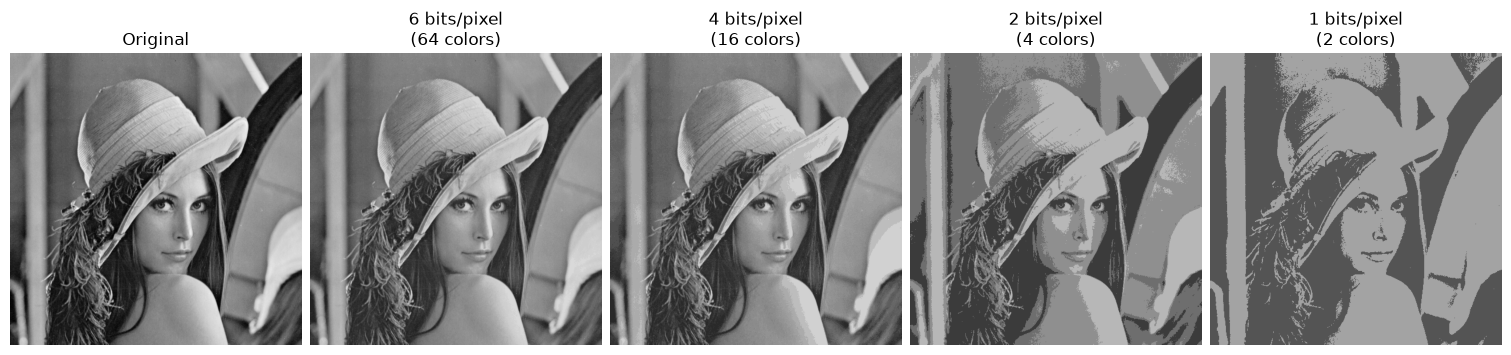

In [57]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

image_1 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena3.tif")
image_2 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")

with urlopen(image_1 ) as response:
    img_1 = Image.open(BytesIO(response.read()))

with urlopen(image_2 ) as response:
    img_2 = Image.open(BytesIO(response.read()))

bits_1 = img_1.tag_v2.get(258)
bits_2 = img_2.tag_v2.get(258)

print(f"Image 1: size {img_1.size} and ", f"bits: {bits_1}.")
print(f"Image 2: size {img_2.size} and ", f"bits: {bits_2}. " f"For this single channel image (grayscale), the number of colors is 2^{"(num_bits)"}")

bits_list = (6, 4, 2, 1)

fig, axes = plt.subplots(1, 5, figsize=(15, 4), constrained_layout=True)

axes[0].imshow(img_2, cmap="gray")
axes[0].set_title("Original")

for ax, bits in zip(axes[1:], bits_list):
    color_count = 2**bits
    quantized = img_2.convert("RGB").quantize(
        colors=color_count,
        method=Image.Quantize.MEDIANCUT,
    )
    ax.imshow(quantized.convert("RGB"))
    ax.set_title(f"{bits} bits/pixel\n({color_count} colors)")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show() 